# Current V1-inspired analysis — square domains

This is a main notebook for the current report. It uses `v1_literature.py`:
the previous cell-pair widths, connectivity matrix, relaxation times and activation
parameters, with a simple domain length. No fitting toward a reference gain
matrix is performed. Missing or parameter-mismatched runs are recomputed;
`RECOMPUTE=True` forces a fresh run.

**Units.** Time is ms; one spatial unit is 0.1 mm. The domain side is
$L=43$ units = 4.3 mm. Activity and additive input are dimensionless.
$J=\kappa G$ is an integrated gain; $p=\kappa-\kappa_c$ measures distance from onset.
The solver uses absolute $\kappa$.

**Biological constraints versus model parameters.** The retained inhibitory motif
follows [Pfeffer et al. (2013)](https://doi.org/10.1038/nn.3446).
[Billeh et al. (2020)](https://doi.org/10.1016/j.neuron.2020.01.040) supplies the
cell-pair distance scales. Its rule $\exp(-r^2/s_{ij}^2)$ becomes
$\Sigma_{ij}=(s_{ij}/100)^2/2$; $s$ itself is not the Gaussian standard deviation
in our $\exp[-r^2/(2\sigma^2)]$ convention. Htr3a-to-VIP reduction and unmeasured
pair substitutions are assumptions. The exact effective gains, $\tau,g,\theta$
are retained model parameters, not values identified uniquely by these papers.
Connection probabilities alone cannot determine integrated rate-model gains.

Billeh's STAR Methods, p. e11, lists $s_{E\to E}=114$,
$s_{E\to PV}=92$, $s_{E\to SST}=103$, $s_{PV\to E}=95$, and
$s_{SST\to E}=85$ μm from Levy and Reyes (2012), and
$s_{PV\to PV}\simeq120$ μm from internal Allen Institute data.
Other inhibitory pairs use 120 μm; E–Htr3a pairs use the corresponding
E–SST scales. Here Htr3a is reduced to VIP. A dash in the displayed
$s$ and $\Sigma$ matrices denotes an absent connection, not zero width.

**Input populations.** Direct visual/thalamic drive to E **and PV** is supported
by [Ji et al. (2016)](https://pubmed.ncbi.nlm.nih.gov/25979090/) and used in Billeh's
model. Equal normalized E/PV strengths are our simplifying assumption; the papers
do not establish that ratio. E-only drive represents a selective-input assumption.
The 1D notebook includes an E-only comparison at the same E-input peak.

**Why $L=43$?** It is a nearby integer choice relative to the earlier 47.6023.
With the restored matrix, the nearest integers 44–51 give an oblique first mode
on the square lattice; 43 gives the axial critical shell $(\pm3,0),(0,\pm3)$.
This supports the axis-aligned stripe construction while preserving increasing
frequency near onset. The domain is a modeling choice, not a measured cortical
period. No gain is changed to obtain this geometry.

The main model has four populations. Simply deleting VIP from the unchanged
matrix gives a **homogeneous** ($k=0$) first Hopf instability. The 1D notebook
(`analysis.ipynb`, Section 7) analyzes a three-population model with E→E
strengthened by 8.04%; on the square torus that model's first shell is the
oblique $|k|^2=8$, so it is not included in this 2D notebook.


In [1]:
from pathlib import Path
import sys, json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Image
from io import BytesIO
def showfig(fig):
    buffer=BytesIO();fig.savefig(buffer,format="png",dpi=130)
    display(Image(data=buffer.getvalue()));plt.close(fig)
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'simulations/v1_literature.py').exists())
if str(ROOT) not in sys.path: sys.path.insert(0,str(ROOT))
from simulations.v1_literature import make_model, coefficients, audit, S_UM
from simulations.main_analysis import run_1d, run_2d, EPS, model_audit
K=4
RECOMPUTE=False
model=make_model(K)
critical,normal,extra=coefficients(model)
print('Populations:',model.names)
print('G (fixed dimensionless effective gains):\n',model.A_p)
def print_widths(title,values):
    print(title)
    for i,row in enumerate(values):
        print(' '.join(f'{value:9.5g}' if model.A_p[i,j]!=0 else '        -' for j,value in enumerate(row)))
print_widths('Billeh distance scale s (micrometers):',S_UM)
print_widths('Sigma (variance in model coordinates; one length unit = 0.1 mm):',model.Sigma)
print_widths('Gaussian standard deviations (micrometers):',100*np.sqrt(model.Sigma))
print('tau (ms):',model.tau,'; sigmoid gains:',model.gain,'; thresholds:',model.theta)
print(f'L = {model.length} model units = {model.length*.1:g} mm')
print(f'Periodic onset: kappa_c={critical.p0:.12f}, k0={critical.mode}, f0={critical.frequency_hz:.6f} Hz')
print('alpha, b, c (1/ms):',normal.alpha,normal.b,normal.c)
print('c_perp (1/ms):',extra['c_perp'])
print('Square-torus spectral/stability checks:',audit(model,critical,normal,extra))


Populations: ('E', 'PV', 'SST', 'VIP')
G (fixed dimensionless effective gains):
 [[  6.22009  -1.45455  -6.48944   0.     ]
 [  5.09798  -0.90615  -8.04066   0.     ]
 [  2.67174   0.        0.      -16.     ]
 [  1.68844   0.       -3.13584   0.     ]]
Billeh distance scale s (micrometers):
      114        95        85         -
       92       120       120         -
      103         -         -       120
      103         -       120         -
Sigma (variance in model coordinates; one length unit = 0.1 mm):
   0.6498   0.45125   0.36125         -
   0.4232      0.72      0.72         -
  0.53045         -         -      0.72
  0.53045         -      0.72         -
Gaussian standard deviations (micrometers):
    80.61    67.175    60.104         -
   65.054    84.853    84.853         -
   72.832         -         -    84.853
   72.832         -    84.853         -
tau (ms): [10. 12. 35. 20.] ; sigmoid gains: [3.47682761 7.34413013 3.74650527 6.        ] ; thresholds: [0.28483799 0

## 1. Periodic torus and reflecting square
The periodic model uses two-dimensional Fourier multipliers
$$\widehat W_{ij}(q_x,q_y)=\kappa G_{ij}
\exp[-\Sigma_{ij}(q_x^2+q_y^2)/2],\quad q_\ell=2\pi n_\ell/L.$$
The reflecting comparison uses the same multiplier with $q_\ell=\pi n_\ell/L$
in a DCT-II cosine basis. It is an even-reflected kernel model; it is not a torus.

Each boundary's first onset is recomputed on its own mode lattice. For four
populations, the periodic representative is $(3,0)$, while the reflecting
representative is $(6,1)$ in the cosine basis. Their onset gains differ slightly.
Each run uses $\kappa=\kappa_c^{\rm boundary}-\epsilon^2$ and the corresponding
$2\omega_0^{\rm boundary}$ input frequency. Thus the comparison fixes distance
below onset, not the absolute gain. Symmetry-related critical modes are included
in the initial perturbation.

Four forcing cases retain peaks $(0,0),(3,0),(0,8),(3,2)$ in units of
$\epsilon^2$, in the order (temporal, spatial). On the torus the spatial input is
$\cos(2q_0x)$. For the reflecting square it is
$\cos(2n_x\pi x/L)\cos(2n_y\pi y/L)$, matched to its selected cosine mode.
The periodic square has an additional traveling-input case.

Direct field runs use $32\times32$ cells, RK4 with $\Delta t=1$ ms, 150 s duration,
and diagnostics every 5 ms. The reflecting comparison is a numerical extension;
the torus amplitude equations are not a proof of its stability.


In [2]:
model,geometries,results,summary,OUT=run_2d(K,recompute=RECOMPUTE)
def show(name): display(Image(filename=str(OUT/name)))
print('Output directory:',OUT)
for boundary,geometry in geometries.items():
    print(boundary,'kappa_c:',geometry.point.p0,'wavevector:',geometry.wavevector,'frequency (Hz):',geometry.point.frequency_hz)


Loaded matching run: /Users/jhpaeng306/GitHub/mcn_project/simulations/output/main_literature/4pop_2d/field_periodic.npz
Loaded matching run: /Users/jhpaeng306/GitHub/mcn_project/simulations/output/main_literature/4pop_2d/field_reflect.npz
Output directory: /Users/jhpaeng306/GitHub/mcn_project/simulations/output/main_literature/4pop_2d
periodic kappa_c: 0.7491489064741298 wavevector: (3, 0) frequency (Hz): 13.207708487219426
reflect kappa_c: 0.7491485725294464 wavevector: (6, 1) frequency (Hz): 13.253103238600493


## 2. Four-case comparison and evolution
Final panels subtract the spatial mean and use a common color scale. Contrast
includes all nonconstant modes. Selected-mode amplitudes are normalized as real
Fourier/cosine reconstruction amplitudes and displayed as 100-ms RMS values.
Snapshot magnitudes also depend on the oscillation phase at the displayed time.


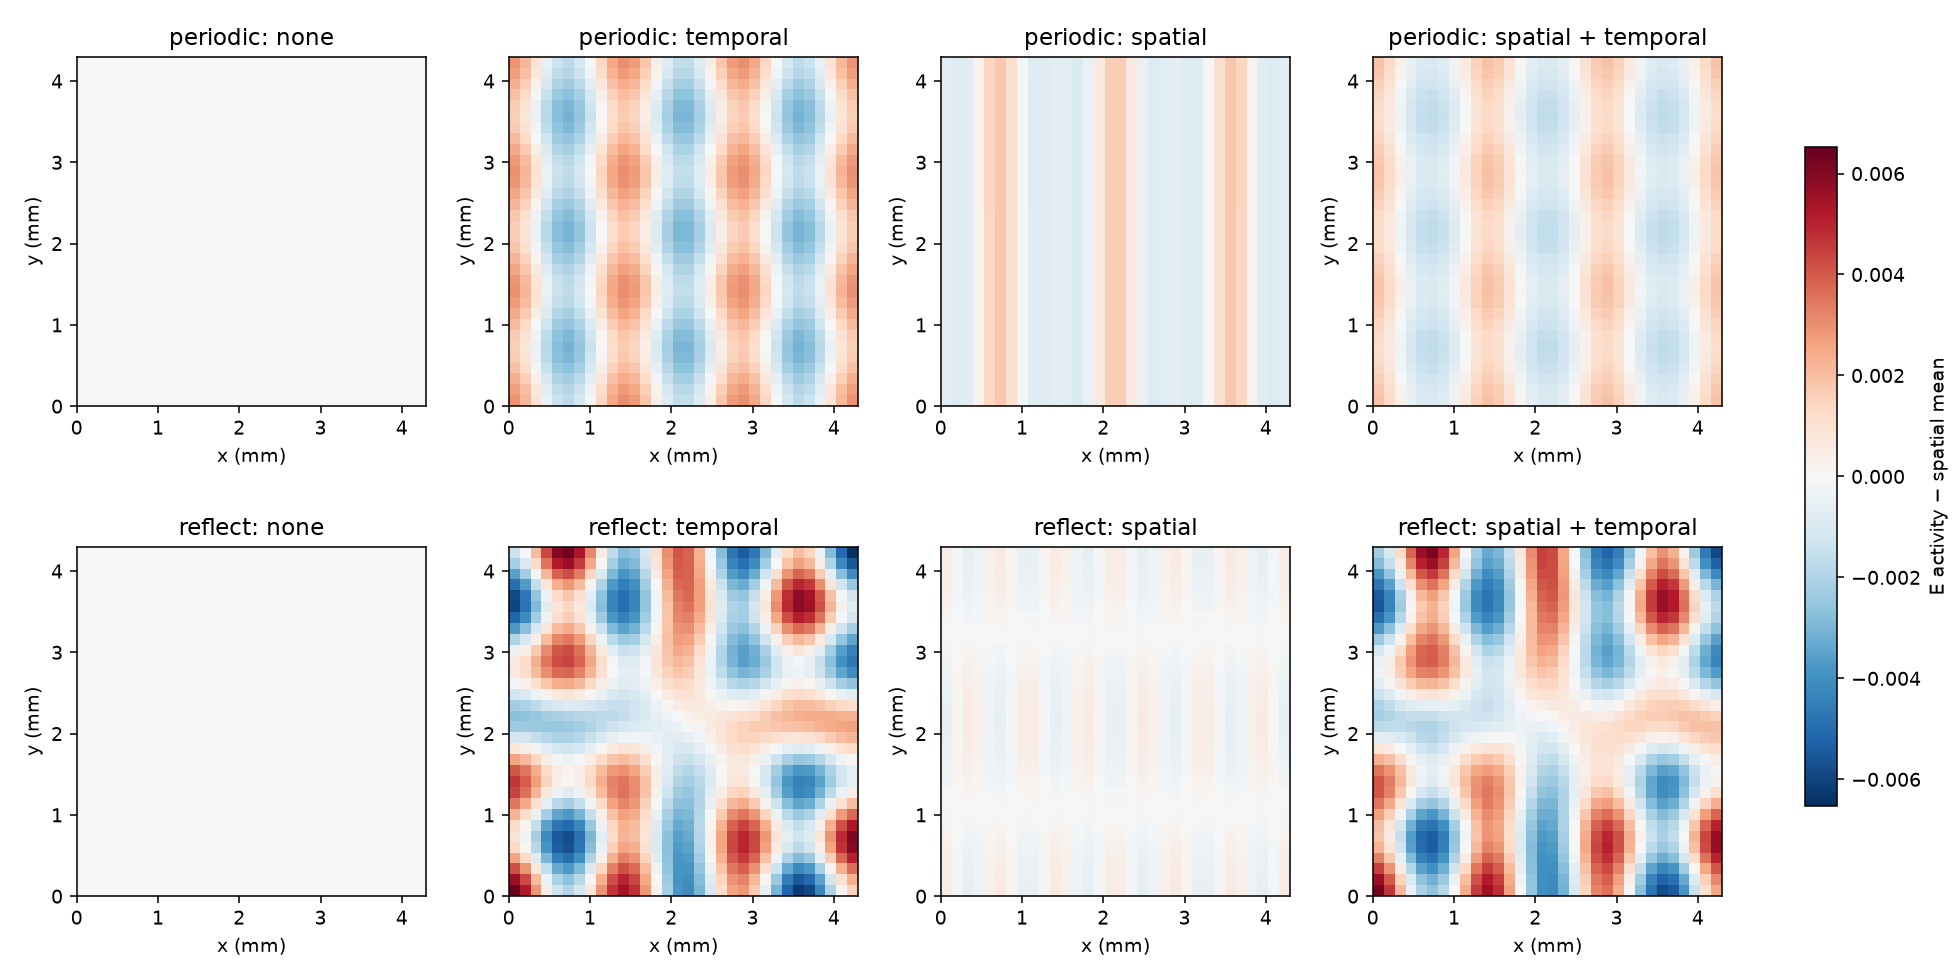

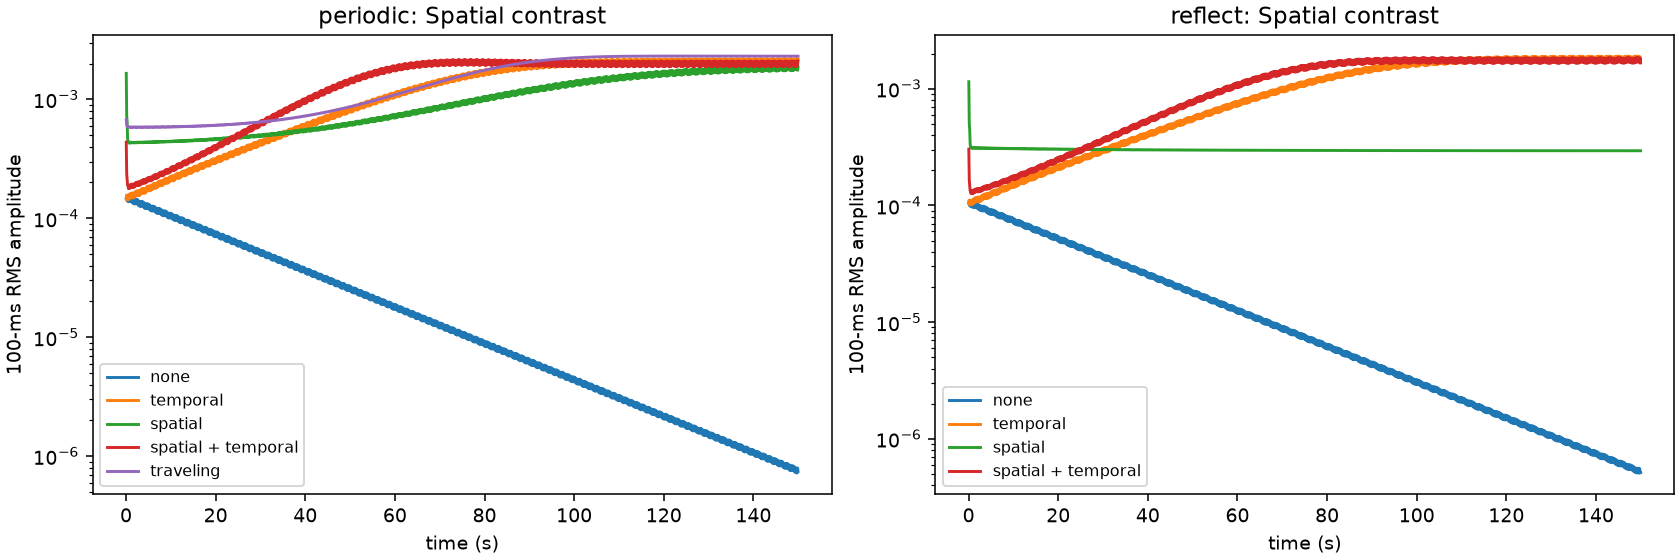

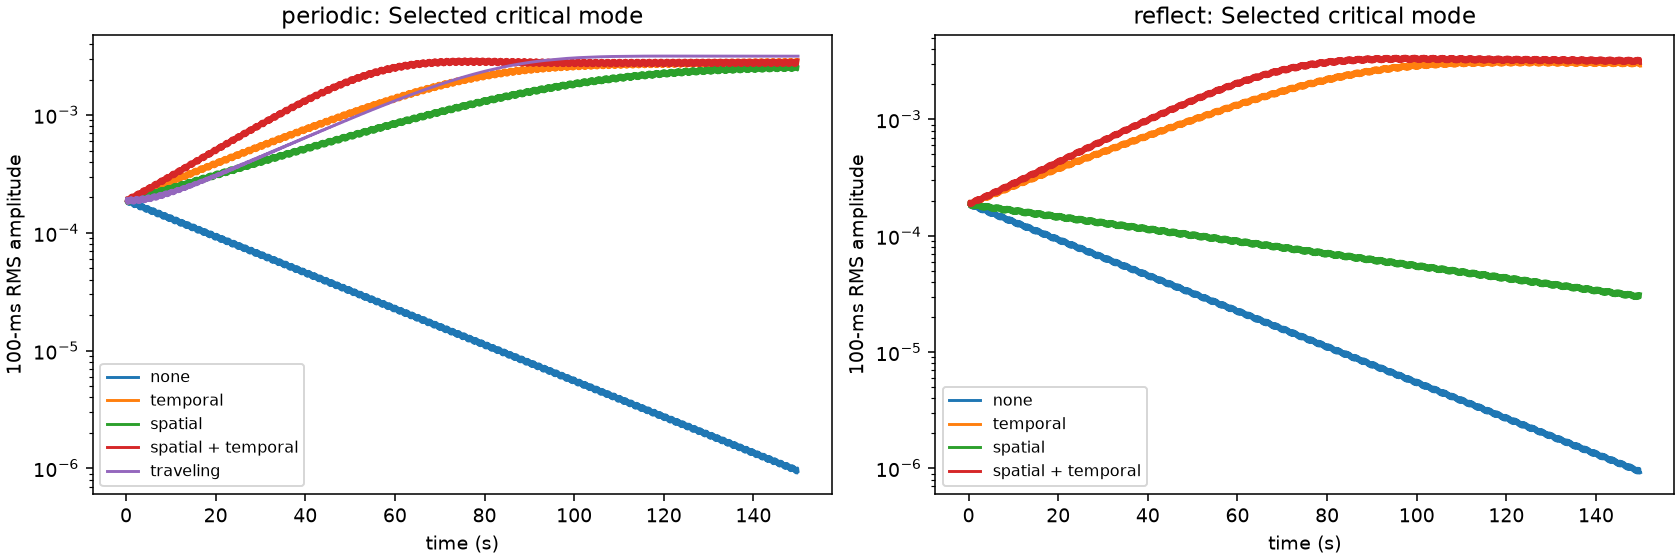

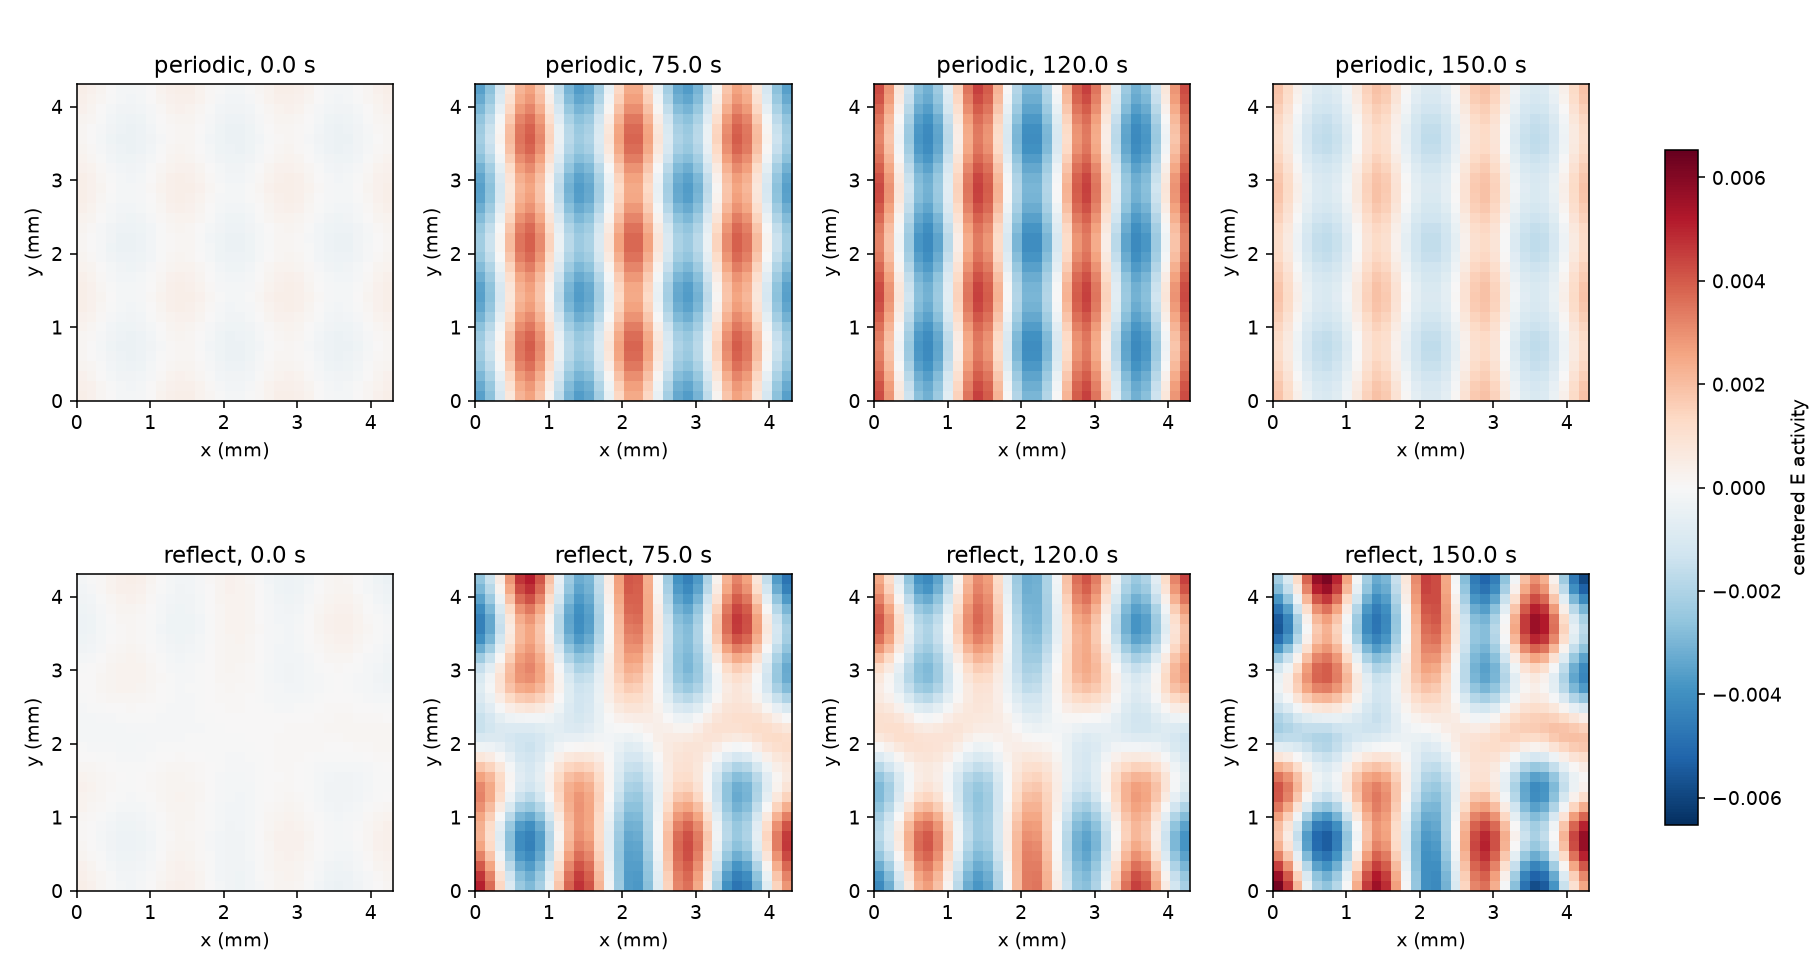

In [3]:
show('final_state_comparison.png')
show('pattern_contrast.png')
show('critical_mode_amplitude.png')
show('combined_evolution.png')


## 3. Traveling input along x: stripes parallel to y
On the square torus,
$$I(x,y,t)=2\epsilon^2(1,1,0,0)^T\cos(2q_0x-2\omega_0t)$$
The input is uniform in $y$. The desired
stripes are parallel to the $y$ axis: activity varies along $x$.
The initial condition includes an orthogonal critical mode and generic noise.
The mode and transverse-RMS histories test whether these perturbations decay.
This is a finite-duration field test, alongside the cubic stability inequalities;
it is not a general nonlinear PDE stability proof.


Traveling case: {'kappa': 0.7487489064741298, 'p': -0.00039999999999995595, 'critical_initial': 0.00014142066705255098, 'critical_late': 0.0023732328136186007, 'E_mode_late_rms': 0.0015814779334347492, 'mode_frequency_hz': 13.2, 'transverse_initial': 6.90296070213333e-05, 'transverse_final': 4.0974370395585965e-09}


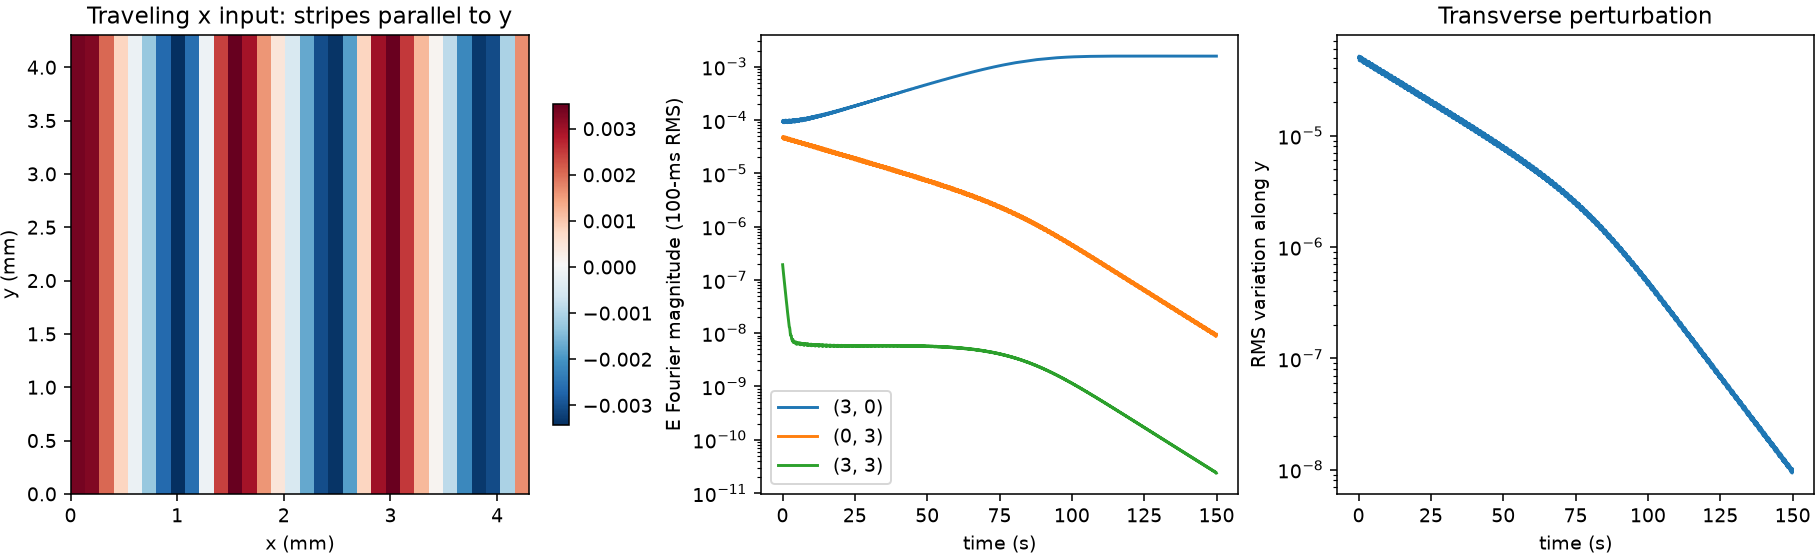

In [4]:
show('traveling_stripes.png')
print('Traveling case:',summary['periodic']['cases']['traveling'])


## 4. Quantitative diagnostics
`critical_late` uses the Hopf-eigenvector projection for periodic fields and the population-vector norm of the cosine coefficient for reflecting fields; these quantities should not be directly compared. `E_mode_late_rms` is the raw coefficient RMS. Frequency peaks from decayed modes have negligible power and are not evidence of an oscillatory pattern.

In [5]:
for boundary,record in summary.items():
    print('\n',boundary)
    for label,metrics in record['cases'].items(): print(label,metrics)



 periodic
none {'kappa': 0.7487489064741298, 'p': -0.00039999999999995595, 'critical_initial': 0.00014142066705255098, 'critical_late': 9.426444995426301e-07, 'E_mode_late_rms': 6.355747236828002e-07, 'mode_frequency_hz': 13.2, 'transverse_initial': 6.90296070213333e-05, 'transverse_final': 3.4031996664975755e-07}
temporal {'kappa': 0.7487489064741298, 'p': -0.00039999999999995595, 'critical_initial': 0.00014142066705255098, 'critical_late': 0.0021006230221244236, 'E_mode_late_rms': 0.0013998847652257436, 'mode_frequency_hz': 13.2, 'transverse_initial': 6.90296070213333e-05, 'transverse_final': 0.00041835819822348463}
spatial {'kappa': 0.7487489064741298, 'p': -0.00039999999999995595, 'critical_initial': 0.00014142066705255098, 'critical_late': 0.0018753190209139445, 'E_mode_late_rms': 0.0012497181554064149, 'mode_frequency_hz': 13.2, 'transverse_initial': 6.90296070213333e-05, 'transverse_final': 1.361972787699497e-07}
spatial + temporal {'kappa': 0.7487489064741298, 'p': -0.00039999

## 5. Inspect every population
Change the boundary and case selectors. These panels have separate color scales; use the earlier common-scale figure for comparisons across cases.

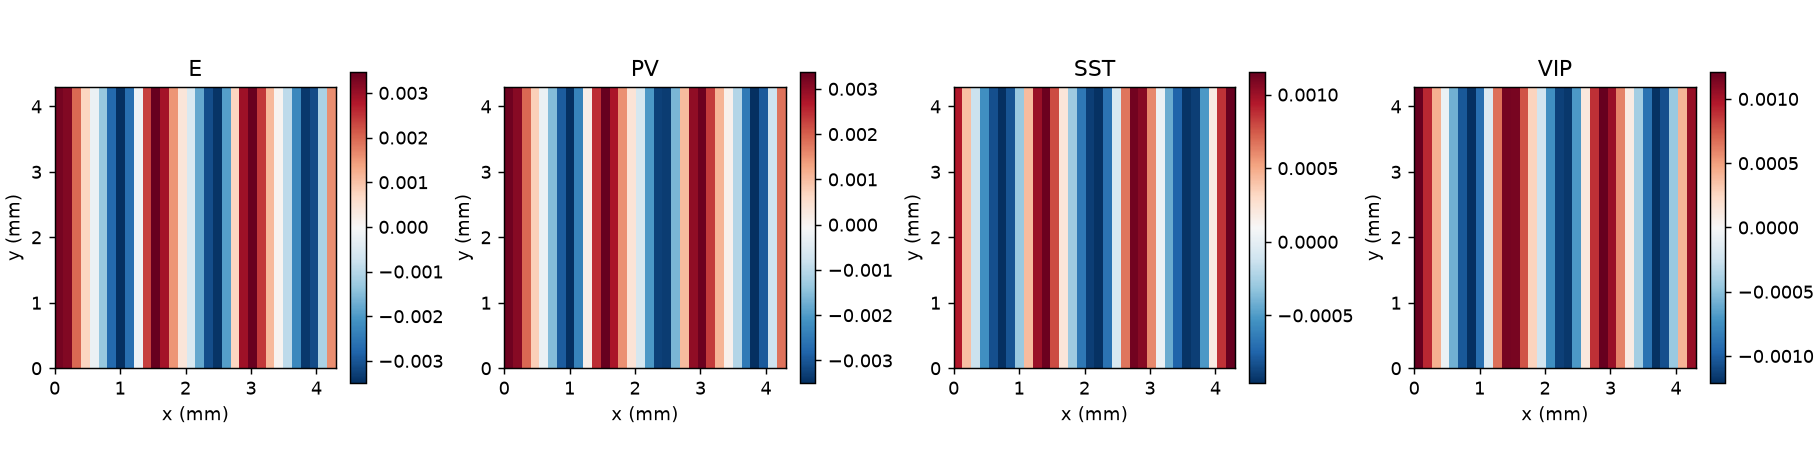

In [6]:
SELECT_BOUNDARY='periodic'
SELECT_CASE='traveling'
selected=results[SELECT_BOUNDARY]
j=list(selected['labels']).index(SELECT_CASE)
fig,axs=plt.subplots(1,K,figsize=(3.5*K,3.5),layout='constrained',squeeze=False)
for pop,ax in enumerate(axs[0]):
    u=selected['final'][j,pop];u=u-u.mean()
    image=ax.imshow(u.T,origin='lower',extent=[0,model.length*.1,0,model.length*.1],cmap='RdBu_r')
    ax.set(title=model.names[pop],xlabel='x (mm)',ylabel='y (mm)')
    fig.colorbar(image,ax=ax,shrink=.7)
showfig(fig)


## Reproducibility and numerical limits
The parameter manifest, direct field arrays and figure files are saved under the
printed output directory. The cache fingerprint includes all model coefficients,
boundary, forcing, grid, duration, time step and seed. Setting `RECOMPUTE=True`
reruns the full simulations. The four-population matrix is fixed. The unmodified
three-population block, `make_model(3, submatrix=True)`, has a homogeneous first onset;
`make_model(3)` is the E→E-strengthened variant used in Section 7 of the 1D notebook.

`tests/test_main_analysis.py` verifies restoration of the previous coefficients,
the increasing eigenvalue derivative, cubic stability conditions, input targeting,
FFT agreement, time-step refinement and cache sensitivity. `v1_three_four_population.ipynb`
compares the three- and four-population dispersion curves with these same coefficients;
`output/v1_simple/` results use the superseded integer-gain example.
Finite-grid simulations support the mechanism; they do not replace a full
convergence or field-stability proof.
